# NAME: JONATHAN AMEGBOR
# ID: 202520493

# Exercise 2: Social Network Analysis

## Task 1: Network Construction and Basic Statistics

In [2]:
import subprocess
subprocess.run(["pip", "install", "python-louvain"], capture_output=True)

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import community as community_louvain
import time
import warnings
warnings.filterwarnings("ignore")

from networkx.algorithms.community import label_propagation_communities

print("All libraries imported successfully")

All libraries imported successfully


Basic Network Statistics:
  Nodes:           4,039
  Edges:           88,234
  Density:         0.010820
  Average Degree:  43.69


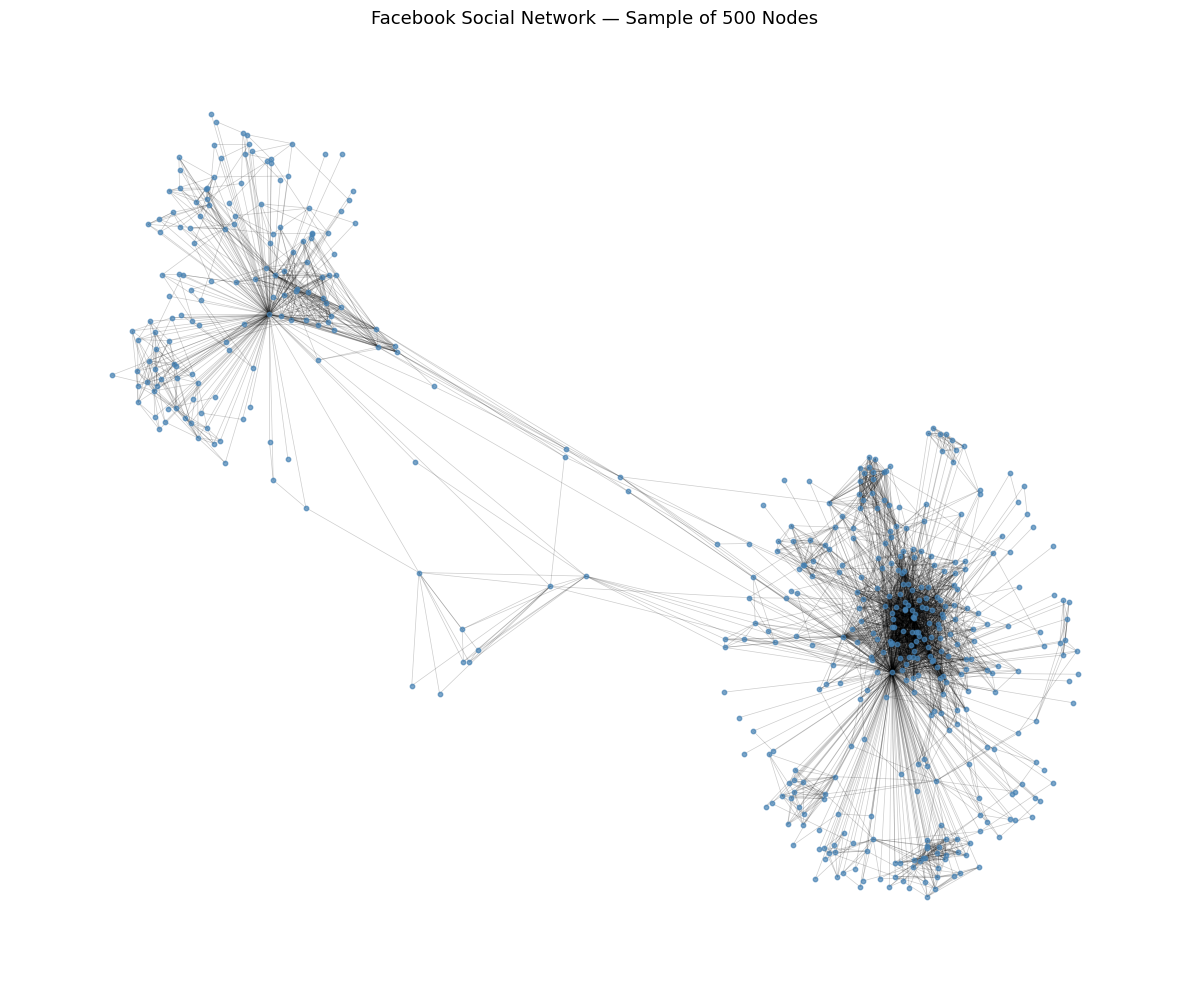

In [4]:

# Load using full path
path = 'facebook_combined-1.txt'

with open(path, 'rb') as f:
    G = nx.read_edgelist(f, nodetype=int)

# Basic statistics
num_nodes  = G.number_of_nodes()
num_edges  = G.number_of_edges()
density    = nx.density(G)
avg_degree = sum(dict(G.degree()).values()) / num_nodes

print("Basic Network Statistics:")
print(f"  Nodes:           {num_nodes:,}")
print(f"  Edges:           {num_edges:,}")
print(f"  Density:         {density:.6f}")
print(f"  Average Degree:  {avg_degree:.2f}")

# Visualise — sample 500 nodes for readability
sample_nodes = list(G.nodes())[:500]
G_sample = G.subgraph(sample_nodes)

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_sample, seed=42)
nx.draw_networkx_nodes(G_sample, pos, node_size=10, node_color='steelblue', alpha=0.7)
nx.draw_networkx_edges(G_sample, pos, alpha=0.2, width=0.5)
plt.title('Facebook Social Network — Sample of 500 Nodes', fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Edge Betweenness Centrality

Computing edge betweenness centrality


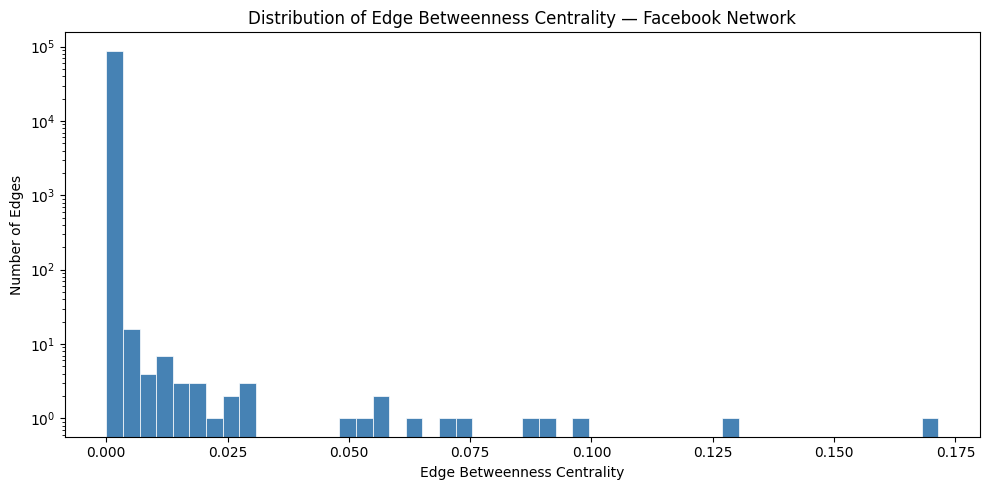


Top 5 Edges by Edge Betweenness Centrality:
  Edge (107, 1684): 0.171493
  Edge (107, 1085): 0.129675
  Edge (1085, 3437): 0.096580
  Edge (567, 3437): 0.092169
  Edge (0, 107): 0.088355


In [5]:
print("Computing edge betweenness centrality")
edge_bc = nx.edge_betweenness_centrality(G)

edge_values = list(edge_bc.values())

plt.figure(figsize=(10, 5))
plt.hist(edge_values, bins=50, color='steelblue', edgecolor='white', linewidth=0.5)
plt.title('Distribution of Edge Betweenness Centrality — Facebook Network')
plt.xlabel('Edge Betweenness Centrality')
plt.ylabel('Number of Edges')
plt.yscale('log')
plt.tight_layout()
plt.show()

top5_edges = sorted(edge_bc.items(), key=lambda x: x[1], reverse=True)[:5]
print("\nTop 5 Edges by Edge Betweenness Centrality:")
for edge, val in top5_edges:
    print(f"  Edge {edge}: {val:.6f}")

## Task 3: Community Detection

### Algorithm 1: Label Propagation

In [6]:
print("Running Label Propagation...")
lpa_communities = list(label_propagation_communities(G))
lpa_sizes = sorted([len(c) for c in lpa_communities], reverse=True)

num_lpa      = len(lpa_communities)
avg_lpa      = sum(lpa_sizes) / num_lpa
modularity_lpa = nx.algorithms.community.modularity(G, lpa_communities)

print(f"  Communities: {num_lpa}")
print(f"  Average Size: {avg_lpa:.1f}")
print(f"  Modularity: {modularity_lpa:.4f}")
print(f"  Largest 5 communities: {lpa_sizes[:5]}")

Running Label Propagation...
  Communities: 44
  Average Size: 91.8
  Modularity: 0.7368
  Largest 5 communities: [1030, 753, 547, 469, 226]


## Algorithm 2: Louvain Community Detection

In [7]:
print("Running Louvain community detection...")
start = time.time()

# Run Louvain
partition = community_louvain.best_partition(G)
elapsed = round(time.time() - start, 1)

# Calculate statistics
communities_louvain = {}
for node, comm_id in partition.items():
    if comm_id not in communities_louvain:
        communities_louvain[comm_id] = []
    communities_louvain[comm_id].append(node)

louvain_sizes = sorted([len(c) for c in communities_louvain.values()], reverse=True)
num_louvain = len(communities_louvain)
avg_louvain = sum(louvain_sizes) / num_louvain
modularity_louvain = community_louvain.modularity(partition, G)

print(f"  Communities: {num_louvain}")
print(f"  Average Size: {avg_louvain:.1f}")
print(f"  Largest Community: {louvain_sizes[0]}")
print(f"  Modularity: {modularity_louvain:.4f}")
print(f"  Time: {elapsed}s")
print("")
print(f"Community sizes: {louvain_sizes}")

Running Louvain community detection...
  Communities: 16
  Average Size: 252.4
  Largest Community: 548
  Modularity: 0.8349
  Time: 1.8s

Community sizes: [548, 535, 433, 432, 423, 354, 321, 237, 226, 206, 128, 73, 60, 25, 19, 19]


### Algorithm Comparison

In [8]:

comparison = pd.DataFrame({
    "Algorithm": ["Label Propagation", "Louvain"],
    "Communities": [num_lpa, num_louvain],
    "Avg Size": [round(avg_lpa, 1), round(avg_louvain, 1)],
    "Modularity": [round(modularity_lpa, 4), round(modularity_louvain, 4)]
})
print("Algorithm Comparison:")
display(comparison.set_index("Algorithm"))

Algorithm Comparison:


,Communities,Avg Size,Modularity
Algorithm,,,
Label Propagation,44,91.8,0.7368
Louvain,16,252.4,0.8349


### Community Detection Visualisations

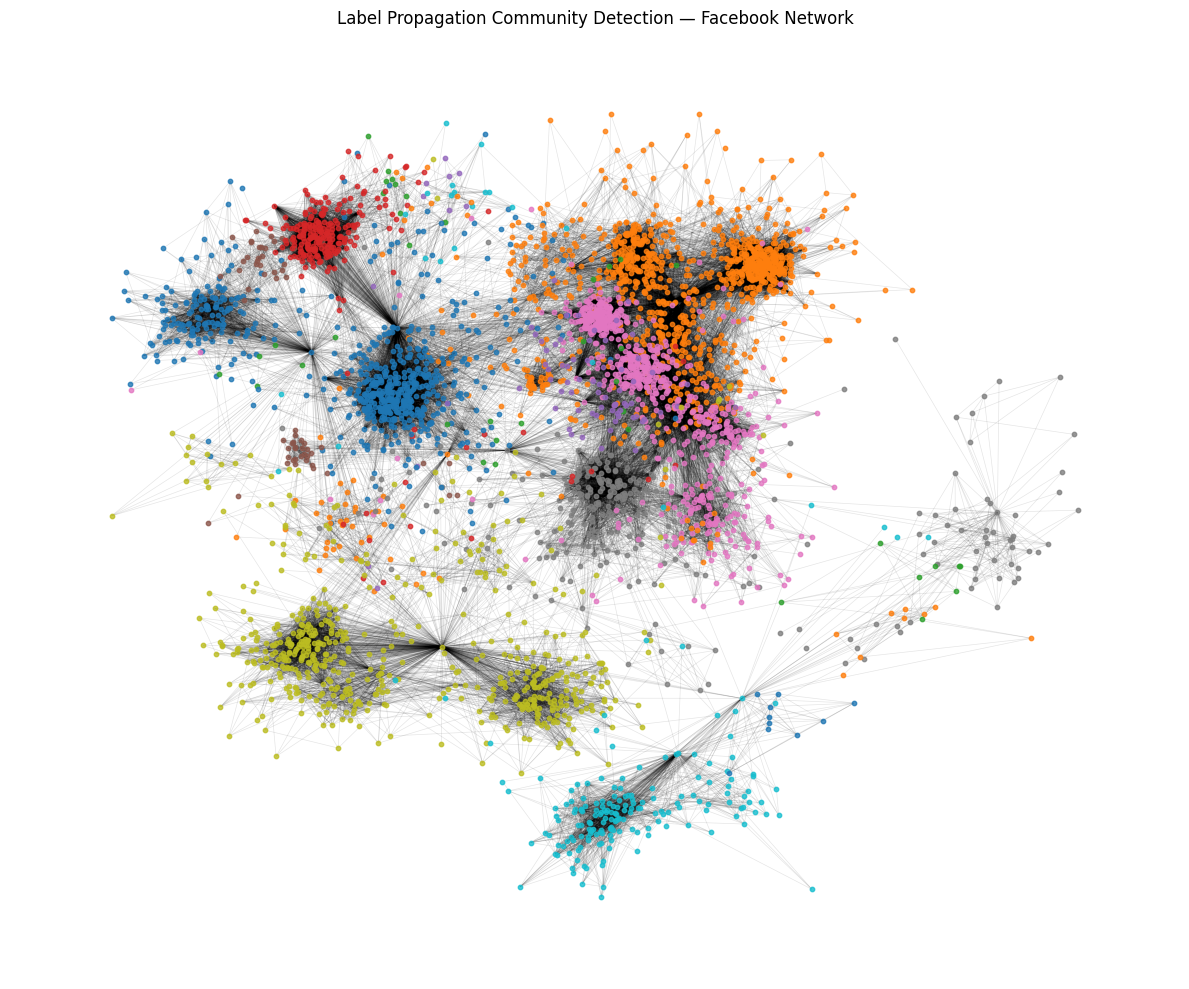

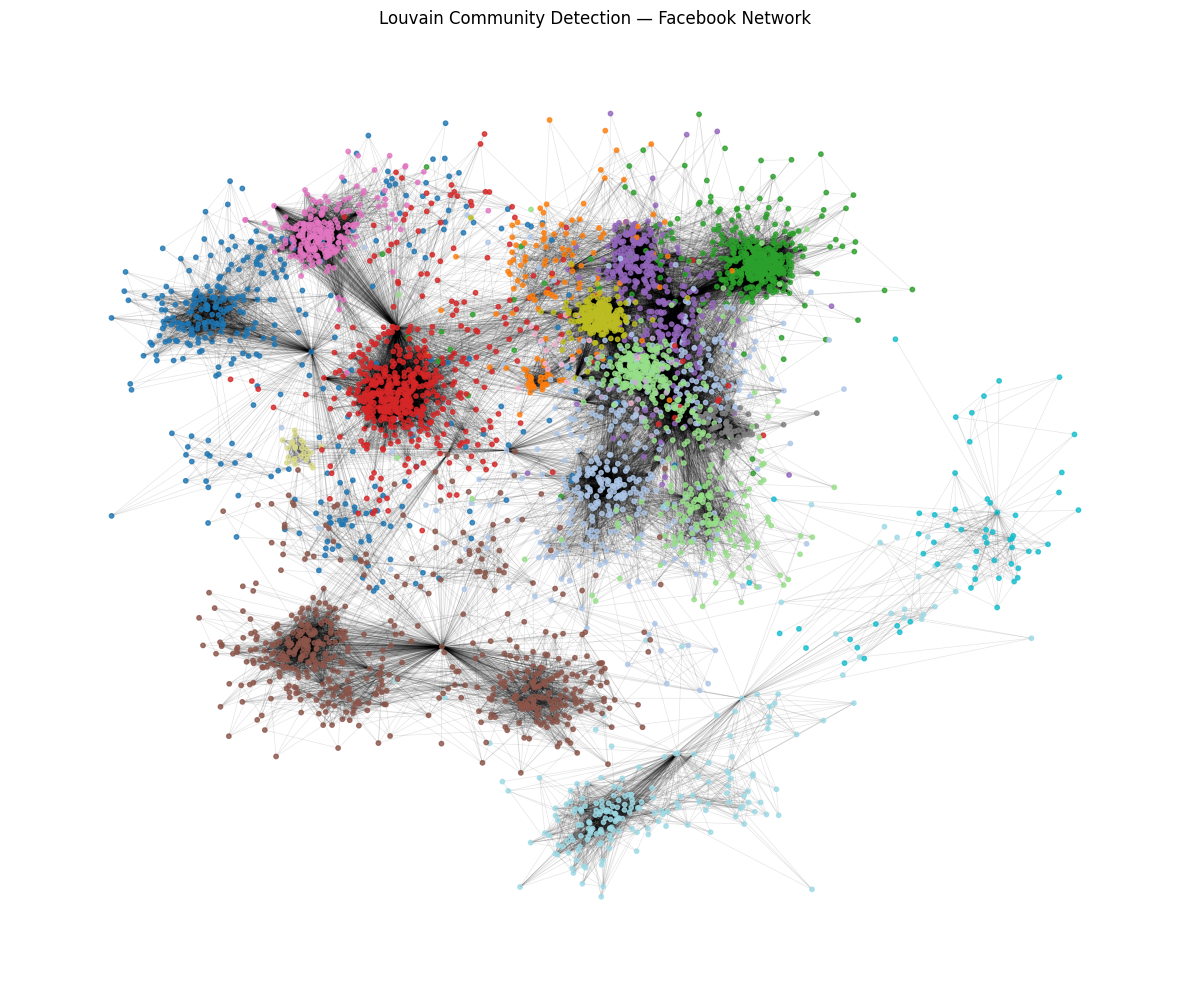

Figures saved: lpa_communities.png and louvain_communities.png


In [9]:
# Label Propagation visualisation
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
lpa_colors = [f"C{i}" for i in range(len(lpa_communities))]
for i, community in enumerate(lpa_communities):
    nx.draw_networkx_nodes(G, pos, nodelist=list(community),
                           node_color=lpa_colors[i], node_size=10, alpha=0.8)
nx.draw_networkx_edges(G, pos, alpha=0.1, width=0.5)
plt.title("Label Propagation Community Detection — Facebook Network")
plt.axis("off")
plt.tight_layout()
plt.savefig('lpa_communities.png', dpi=150, bbox_inches='tight')
plt.show()

# Louvain visualisation
plt.figure(figsize=(12, 10))
louvain_colors = [partition[node] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_color=louvain_colors, node_size=10,
                       cmap=plt.cm.tab20, alpha=0.8)
nx.draw_networkx_edges(G, pos, alpha=0.1, width=0.5)
plt.title("Louvain Community Detection — Facebook Network")
plt.axis("off")
plt.tight_layout()
plt.savefig('louvain_communities.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figures saved: lpa_communities.png and louvain_communities.png")